# Human keypoints with YOLO26-pose

Robots that share space with people need to know more than "there is a person in this box":
where are the hands, is someone pointing, is an arm raised to say *stop*? **Human pose
estimation** answers this by localising a fixed set of body **keypoints** for every person.

In this notebook we:

1. run the single-stage **YOLO26n-pose** and **YOLO26s-pose** models (Ultralytics) on sample images,
2. look inside the output (boxes, 17 COCO keypoints, per-keypoint confidences),
3. implement **Object Keypoint Similarity (OKS)** by hand, cross-check it against Ultralytics, and use
   it to score predictions against the COCO8-Pose ground truth,
4. run the official pose **mAP** evaluation (and explain why 4 validation images are only a smoke test),
5. measure how accuracy, latency and VRAM change with input resolution (a proxy for "people far away"),
6. turn keypoints into something a robot can act on: joint angles and a "hand raised" gesture rule.

**What you'll learn:** the COCO keypoint format, how one-stage pose models differ from top-down
pipelines, OKS and pose mAP, and the accuracy/latency trade-off of model size and input size.

**Prerequisites:** object detection basics (boxes, IoU, mAP; see project 03). Data and weights:
`make data-07_pose_estimation` (COCO8-Pose 0.3 MB, YOLO26n/s-pose 8 + 24 MB).

## Setup

Imports, seeding/device summary, repository-relative paths and the plotting style. Ultralytics is
told not to auto-install packages (that would bypass the repository's constraints file), and its
logger is set to errors only so the notebook output stays short.

In [1]:
# --- Setup: imports, device, paths, plotting style ---
# YOLO_AUTOINSTALL must be set *before* ultralytics is imported, otherwise it may pip-install
# missing extras at runtime without our constraints file.
import os

os.environ["YOLO_AUTOINSTALL"] = "false"
import io
import logging
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from ultralytics import YOLO
from ultralytics.utils import ASSETS, LOGGER
from ultralytics.utils.metrics import OKS_SIGMA, kpt_iou
from ultralytics.utils.torch_utils import get_flops, get_num_params

from cvlab import device as cvdevice
from cvlab import io as cvio
from cvlab import viz
from cvlab.bench import benchmark

LOGGER.setLevel(logging.ERROR)  # silence per-call logs (they also contain absolute paths)
device = cvdevice.setup(seed=0)
viz.set_style()

PROJECT = "07_pose_estimation"
ROOT = cvio.repo_root()
PROJ_DIR = cvio.project_dir(PROJECT)
sys.path.insert(0, str(PROJ_DIR / "scripts"))  # project helpers (keypoints.py)
import keypoints as kp

WEIGHTS = cvio.weights_dir("ultralytics")
COCO8 = cvio.data_dir("ultralytics", "coco8-pose")
RESULTS_DIR = PROJ_DIR / "results"
RUNS = cvio.runs_dir(PROJECT)
for p in (WEIGHTS, COCO8):
    print(f"{p.relative_to(ROOT)}: {'ok' if p.exists() else 'MISSING - run make data-07_pose_estimation'}")


def show_jpeg(fig, quality=85):
    # Photo-heavy figures are displayed as JPEG to keep the committed notebook small.
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=100, pil_kwargs={"quality": quality})
    plt.close(fig)
    display(Image(data=buf.getvalue(), format="jpeg"))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
weights/ultralytics: ok
data/ultralytics/coco8-pose: ok


## 1. The COCO-17 keypoint format

COCO annotates 17 keypoints per person, each as $(x, y, v)$ with a visibility flag
$v \in \{0: \text{not labelled}, 1: \text{labelled but occluded}, 2: \text{visible}\}$.
The **skeleton** is a list of keypoint pairs that we draw as limbs. Each keypoint also has a
**sigma** $\sigma_i$: the standard deviation of human annotators' clicks for that joint, relative to
the person's size. Eyes are clicked consistently (small $\sigma$), hips hide under clothing (large $\sigma$).
These sigmas drive the OKS metric below.

The table also lists `flip_idx`, the left/right permutation needed whenever an image is mirrored
(data augmentation, flip test-time augmentation).

In [2]:
# --- Inspect the keypoint definition used by COCO and Ultralytics ---
# Our hand-written sigma table must match Ultralytics' (OKS_SIGMA) for the cross-checks later.
assert np.allclose(kp.COCO_SIGMAS, OKS_SIGMA)
kpt_table = pd.DataFrame(
    {"name": kp.KPT_NAMES, "sigma": kp.COCO_SIGMAS, "flip_idx": kp.FLIP_IDX}
)
kpt_table.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
name,nose,left_eye,right_eye,left_ear,right_ear,left_shoulder,right_shoulder,left_elbow,right_elbow,left_wrist,right_wrist,left_hip,right_hip,left_knee,right_knee,left_ankle,right_ankle
sigma,0.026,0.025,0.025,0.035,0.035,0.079,0.079,0.072,0.072,0.062,0.062,0.107,0.107,0.087,0.087,0.089,0.089
flip_idx,0,2,1,4,3,6,5,8,7,10,9,12,11,14,13,16,15


## 2. Load YOLO26-pose (nano and small)

YOLO-pose is a **one-stage** (bottom-up-free, "detect-and-regress") model: the same dense head that
predicts a person box at each feature-map location also regresses the 17 keypoint offsets and their
confidences, so the cost does not grow with the number of people. This contrasts with
**top-down** pipelines (detect people, crop each one, run a keypoint network per crop; e.g. HRNet,
ViTPose), which are often more accurate on small people but scale linearly with the crowd size.

YOLO26 is Ultralytics' NMS-free generation; its pose head (`Pose26`) is trained with a residual
log-likelihood (RLE) keypoint loss. We load the two smallest variants from `weights/ultralytics/`
and *fuse* them (Conv+BatchNorm folding, training-only branches dropped), which is the graph that
actually runs at inference time.

In [3]:
# --- Load the two pose models, fuse them and report parameters / FLOPs ---
# Explicit paths into weights/ultralytics keep downloads out of the working directory.
MODELS = {"YOLO26n-pose": "yolo26n-pose.pt", "YOLO26s-pose": "yolo26s-pose.pt"}
models, model_info = {}, []
for name, fname in MODELS.items():
    models[name] = YOLO(str(WEIGHTS / fname))
    models[name].fuse()
    model_info.append({"model": name, "params_M": get_num_params(models[name].model) / 1e6,
                       "GFLOPs@640": get_flops(models[name].model, imgsz=640),
                       "file_MB": (WEIGHTS / fname).stat().st_size / 1e6})
pd.DataFrame(model_info).round(2)

,model,params_M,GFLOPs@640,file_MB
0,YOLO26n-pose,2.93,7.57,7.88
1,YOLO26s-pose,10.36,24.12,24.15


## 3. Inference on sample images

`model.predict` returns one `Results` object per image with
`boxes.xyxy` $(N\times4)$, `boxes.conf` $(N)$, `keypoints.xy` $(N\times17\times2)$ in pixels and
`keypoints.conf` $(N\times17)$. We run both models in fp16 (`quantize=16`) at the default
640 px input and draw skeletons ourselves, hiding keypoints with confidence < 0.5.

In [4]:
# --- Predict on the two Ultralytics sample images with both models ---
# Images are read as RGB; ultralytics expects BGR numpy arrays (OpenCV order), so we convert.
samples = {name: cvio.read_image(ASSETS / name) for name in ["bus.jpg", "zidane.jpg"]}
preds = {}
for mname, model in models.items():
    for iname, img in samples.items():
        r = model.predict(img[..., ::-1], imgsz=640, conf=0.25, quantize=16, verbose=False)[0]
        preds[mname, iname] = {
            "boxes": r.boxes.xyxy.cpu().numpy(), "score": r.boxes.conf.cpu().numpy(),
            "kpts": r.keypoints.xy.cpu().numpy(), "kconf": r.keypoints.conf.cpu().numpy(),
        }
        print(f"{mname:13s} {iname:10s}: {len(r.boxes)} people, "
              f"mean keypoint conf {preds[mname, iname]['kconf'].mean():.2f}")

YOLO26n-pose  bus.jpg   : 5 people, mean keypoint conf 0.52


YOLO26n-pose  zidane.jpg: 3 people, mean keypoint conf 0.46


YOLO26s-pose  bus.jpg   : 4 people, mean keypoint conf 0.60


YOLO26s-pose  zidane.jpg: 2 people, mean keypoint conf 0.49


Draw boxes and skeletons (yellow = head/centre, green = left side, orange = right side of the
*person*, not of the image).

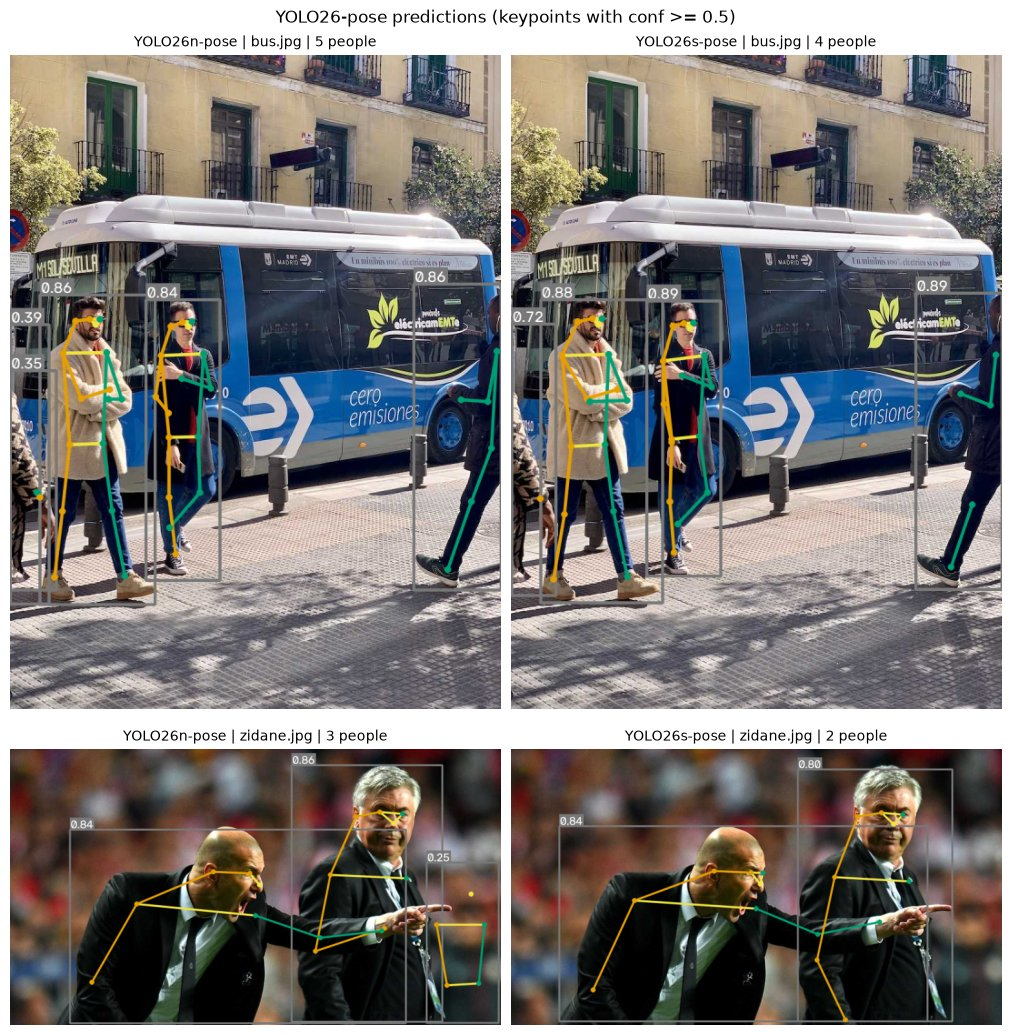

In [5]:
# --- Visualise predictions: rows = images, columns = models (row heights follow image aspect) ---
ratios = [samples[i].shape[0] / samples[i].shape[1] for i in samples]
fig, axes = plt.subplots(2, 2, figsize=(10, 5 * sum(ratios) + 0.8), gridspec_kw={"height_ratios": ratios})
for r, iname in enumerate(samples):
    for c, mname in enumerate(models):
        p = preds[mname, iname]
        vis = viz.draw_boxes(samples[iname], p["boxes"], scores=p["score"], class_ids=[7] * len(p["boxes"]))
        axes[r, c].imshow(cvio.resize_max(kp.draw_pose(vis, p["kpts"], p["kconf"], thr=0.5), 720))
        axes[r, c].set_title(f"{mname} | {iname} | {len(p['boxes'])} people", fontsize=10)
        axes[r, c].axis("off")
fig.suptitle("YOLO26-pose predictions (keypoints with conf >= 0.5)")
viz.savefig(fig, PROJECT, "yolo26_pose_samples")
show_jpeg(fig)

### Per-keypoint confidence

Keypoint confidence is the model's estimate that a joint is visible *and* well localised. People cut
by the image border or occluded by others get low scores on the hidden joints. A downstream robot
behaviour should gate on these scores rather than on the box score alone.

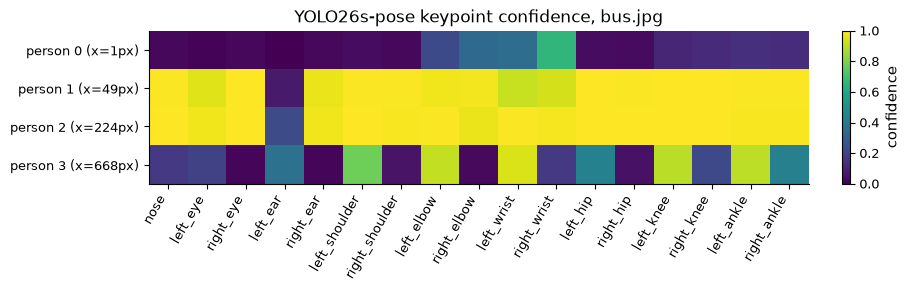

In [6]:
# --- Heat map of keypoint confidences for every person in bus.jpg (YOLO26s-pose) ---
p = preds["YOLO26s-pose", "bus.jpg"]
order = np.argsort(p["boxes"][:, 0])  # sort people left -> right in the image
fig, ax = plt.subplots(figsize=(9, 2.8))
im = ax.imshow(p["kconf"][order], vmin=0, vmax=1, cmap="viridis", aspect="auto")
ax.set_xticks(range(17), kp.KPT_NAMES, rotation=60, ha="right")
ax.set_yticks(range(len(order)), [f"person {i} (x={p['boxes'][j, 0]:.0f}px)" for i, j in enumerate(order)])
ax.set_title("YOLO26s-pose keypoint confidence, bus.jpg")
ax.grid(False)
fig.colorbar(im, ax=ax, label="confidence")
plt.show()

## 4. Object Keypoint Similarity (OKS)

Box detectors are scored with IoU; pose models are scored with **OKS**, a soft per-person
similarity in $[0, 1]$:

$$
\mathrm{OKS} = \frac{\sum_i \exp\!\left(-\dfrac{d_i^2}{2\,s^2 k_i^2}\right)\,\delta(v_i>0)}{\sum_i \delta(v_i>0)},
\qquad k_i = 2\sigma_i ,
$$

where $d_i$ is the pixel distance between predicted and ground-truth keypoint $i$, $s^2$ is the
object's area (COCO uses the segmentation area; Ultralytics approximates it as $0.53\times$ box area)
and only labelled keypoints ($v_i > 0$) count. Each term is a Gaussian "is this close enough
*for this joint and this person size*?" score: a 10 px error on a small, far-away person is
severe, the same error on a close-up is negligible.

**Pose AP** reuses the detection AP machinery with OKS in place of IoU: a prediction is a true
positive at threshold $\tau$ if it matches an unmatched GT with $\mathrm{OKS}\ge\tau$;
**mAP50-95** averages AP over $\tau \in \{0.50, 0.55, \dots, 0.95\}$.

We implemented OKS in `scripts/keypoints.py`; first check it against Ultralytics' `kpt_iou`.

In [7]:
# --- Cross-check our OKS implementation against Ultralytics on random poses ---
rng = np.random.default_rng(0)
gt = np.concatenate([rng.uniform(50, 400, (4, 17, 2)), np.full((4, 17, 1), 2.0)], axis=-1)
gt[0, 12:, 2] = 0  # some unlabelled keypoints
pr = np.concatenate([gt[..., :2] + rng.normal(0, 6, gt[..., :2].shape), np.ones((4, 17, 1))], -1)
areas = rng.uniform(3e3, 3e4, 4)
ours = kp.oks_matrix(gt, areas, pr)
ref = kpt_iou(torch.tensor(gt), torch.tensor(pr), torch.tensor(areas), sigma=OKS_SIGMA).numpy()
print("max |ours - ultralytics| =", np.abs(ours - ref).max())

max |ours - ultralytics| = 2.822968081517274e-09


### Scoring predictions on COCO8-Pose validation images

COCO8-Pose contains 8 COCO images (4 train, 4 val) with YOLO-format labels:
`cls cx cy w h` followed by 17 triplets `x y v`, all normalised to $[0, 1]$. We match predictions
to ground truth one-to-one with the Hungarian algorithm on OKS and report each person's OKS
(0 when a person is missed).

In [8]:
# --- Load the 4 validation images + labels and score both models with OKS ---
val_imgs = sorted((COCO8 / "images" / "val").glob("*.jpg"))
val = []
for f in val_imgs:
    img = cvio.read_image(f)
    h, w = img.shape[:2]
    boxes, kpts_gt, areas = kp.load_yolo_pose_labels(COCO8 / "labels" / "val" / f"{f.stem}.txt", w, h)
    val.append({"name": f.name, "img": img, "boxes": boxes, "kpts": kpts_gt, "areas": areas})

def predict_kpts(model, img, imgsz=640):
    # Run one image and return keypoints (N,17,2), keypoint conf (N,17) and box scores (N,)
    r = model.predict(img[..., ::-1], imgsz=imgsz, conf=0.25, quantize=16, verbose=False)[0]
    return r.keypoints.xy.cpu().numpy(), r.keypoints.conf.cpu().numpy(), r.boxes.conf.cpu().numpy()

rows = []
for v in val:
    for mname, model in models.items():
        k_pred, k_conf, _ = predict_kpts(model, v["img"])
        best = kp.match_by_oks(v["kpts"], v["areas"], k_pred)
        v[mname] = (k_pred, k_conf, best)
        for i, o in enumerate(best):
            rows.append({"image": v["name"], "person": i, "model": mname, "OKS": o,
                         "labelled_kpts": int((v["kpts"][i, :, 2] > 0).sum())})
oks_df = pd.DataFrame(rows)
print(f"{len(val)} val images, {len(oks_df) // len(models)} labelled people")
oks_df.pivot_table(index=["image", "person", "labelled_kpts"], columns="model", values="OKS").round(3)

4 val images, 14 labelled people


model                                  YOLO26n-pose  YOLO26s-pose
image            person labelled_kpts                            
000000000110.jpg 0      11                    0.939         0.934
                 1      8                     0.901         0.931
                 2      6                     0.729         0.721
                 3      7                     0.447         0.393
                 4      10                    0.133         0.312
                 5      7                     0.818         0.791
                 6      6                     0.000         0.519
                 7      10                    0.661         0.702
000000000113.jpg 0      16                    0.863         0.860
                 1      7                     0.886         0.907
                 2      15                    0.956         0.963
000000000136.jpg 0      4                     0.619         0.681
                 1      6                     0.408         0.446
000000000151.jpg 0      3                     0.076         0.273

Ground truth (white) vs YOLO26s-pose (coloured) on the validation images. Persons with few
labelled keypoints (heavily occluded or tiny) are where OKS is least stable.

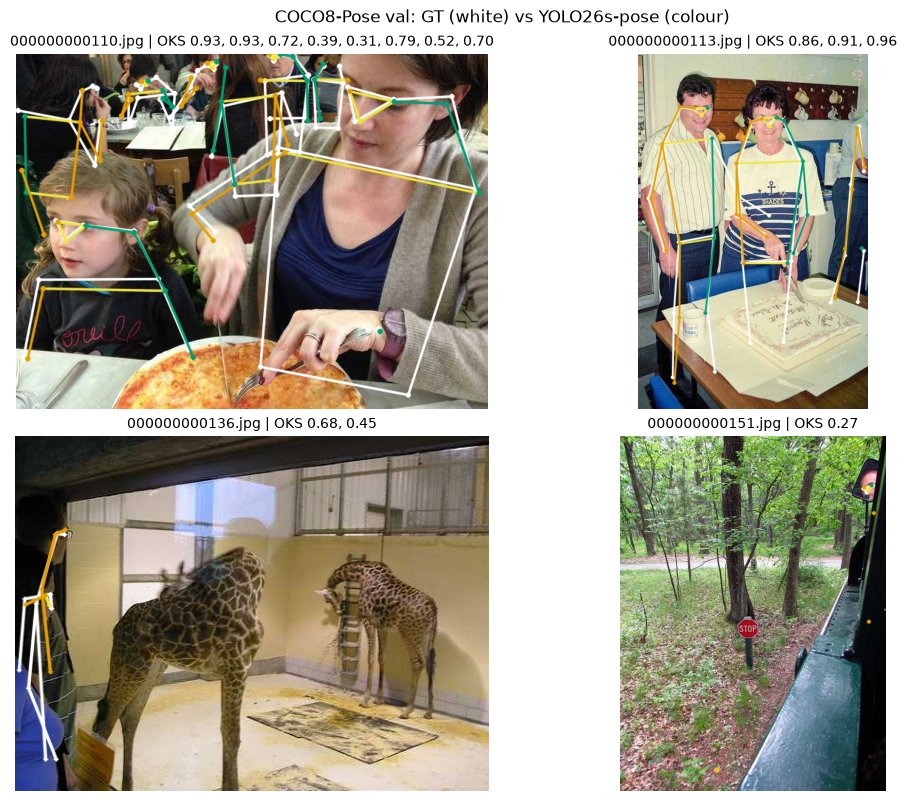

In [9]:
# --- Overlay ground truth and predictions with per-person OKS ---
panels, titles = [], []
for v in val:
    k_pred, k_conf, best = v["YOLO26s-pose"]
    gt_vis = kp.draw_pose(v["img"], v["kpts"][..., :2], (v["kpts"][..., 2] > 0).astype(float),
                          colors=((255, 255, 255),) * 3)
    panels.append(kp.draw_pose(gt_vis, k_pred, k_conf, thr=0.5))
    titles.append(f"{v['name'][:16]} | OKS " + ", ".join(f"{o:.2f}" for o in best))
fig = viz.show_images(panels, titles, ncols=2, size=5.0, suptitle="COCO8-Pose val: GT (white) vs YOLO26s-pose (colour)")
show_jpeg(fig)

## 5. Official validation: box and pose mAP

`model.val(data="coco8-pose.yaml")` runs the full COCO-style evaluation: box mAP (IoU) and pose mAP
(OKS). **Caveat:** with only 4 images and 14 people, a single missed person moves recall by about
7 points, so these numbers are a *smoke test* of the pipeline, not a benchmark. Ultralytics reports
COCO val2017 pose mAP50-95 of 57.2 (n) and 63.0 (s) for YOLO26 at 640 px
([docs](https://docs.ultralytics.com/tasks/pose/)); we did not reproduce those here.

In [10]:
# --- Run the official COCO-style evaluation for both models (fp16, 640 px) ---
val_rows = []
for mname, model in models.items():
    m = model.val(data="coco8-pose.yaml", imgsz=640, batch=4, quantize=16, plots=False,
                  verbose=False, project=str(RUNS), name=f"val_{mname}", exist_ok=True)
    val_rows.append({"model": mname, "box_mAP50": m.box.map50, "box_mAP50-95": m.box.map,
                     "pose_P": m.pose.mp, "pose_R": m.pose.mr,
                     "pose_mAP50": m.pose.map50, "pose_mAP50-95": m.pose.map})
val_df = pd.DataFrame(val_rows).set_index("model")
val_df.round(3)

,box_mAP50,box_mAP50-95,pose_P,pose_R,pose_mAP50,pose_mAP50-95
model,,,,,,
YOLO26n-pose,0.875,0.686,0.79,0.571,0.623,0.419
YOLO26s-pose,0.946,0.717,1.00,0.703,0.758,0.490


## 6. Resolution vs accuracy, latency and memory

A robot sees people at many distances. Shrinking the network input (`imgsz`) is a cheap proxy for
"the person occupies fewer pixels": the keypoints get coarser and OKS drops, while latency falls.
For each model and input size we measure

* **mean OKS** over the 14 labelled people of the val set (missed people count as 0),
* end-to-end `predict()` latency (pre-processing + network + post-processing, batch 1, fp16,
  CUDA-synchronised, after warm-up) on a 640x480 image, and the network-only share that
  Ultralytics reports in `Results.speed["inference"]`,
* **peak VRAM** allocated by PyTorch.

In [11]:
# --- Sweep the input size for both models: mean OKS, latency and peak VRAM ---
IMGSZ = [160, 256, 320, 416, 512, 640]
bench_img = val[0]["img"][..., ::-1].copy()  # BGR, 640x480-ish
for model in models.values():  # global warm-up: CUDA context, cuDNN autotuning, GPU clocks
    benchmark(model.predict, bench_img, imgsz=640, quantize=16, verbose=False, warmup=20, iters=1)
sweep = []
for mname, model in models.items():
    for s in IMGSZ:
        oks_all = []
        for v in val:
            k_pred, _, _ = predict_kpts(model, v["img"], imgsz=s)
            oks_all += list(kp.match_by_oks(v["kpts"], v["areas"], k_pred))
        with cvdevice.track_vram() as mem:
            lat = benchmark(model.predict, bench_img, imgsz=s, quantize=16, verbose=False, warmup=10, iters=50)
        net_ms = np.mean([model.predict(bench_img, imgsz=s, quantize=16, verbose=False)[0].speed["inference"]
                          for _ in range(30)])
        sweep.append({"model": mname, "imgsz": s, "mean_OKS": float(np.mean(oks_all)),
                      "latency_ms": lat["mean_ms"], "latency_p90_ms": lat["p90_ms"],
                      "network_ms": float(net_ms), "peak_vram_MB": mem.peak_mb})
sweep_df = pd.DataFrame(sweep)
sweep_df.round(3)

,model,imgsz,mean_OKS,latency_ms,latency_p90_ms,network_ms,peak_vram_MB
0,YOLO26n-pose,160,0.286,3.654,3.715,2.980,81.759
1,YOLO26n-pose,256,0.398,3.743,3.803,2.928,83.090
2,YOLO26n-pose,320,0.483,3.674,3.752,2.938,81.801
3,YOLO26n-pose,416,0.502,3.876,3.931,2.960,83.207
4,YOLO26n-pose,512,0.568,4.071,4.074,2.974,85.391
5,YOLO26n-pose,640,0.603,3.799,3.868,3.039,88.755
6,YOLO26s-pose,160,0.346,3.653,3.735,2.959,85.131
7,YOLO26s-pose,256,0.555,3.733,3.810,2.995,87.638
8,YOLO26s-pose,320,0.552,3.876,3.950,3.062,83.637
9,YOLO26s-pose,416,0.660,4.104,4.165,3.157,86.918


At batch 1 the time barely depends on the input size or the model (only YOLO26s at 512-640 px is
noticeably slower): the GPU finishes each of the ~130 small layers about as fast as Python can
launch the next kernel, so the run is mostly **launch/overhead bound**. The extra compute of the
larger model shows fully only when the GPU is kept busy, e.g. with batches (several cameras, or
offline processing). `predict()` on a list of images runs them as one
batch; the numbers include the CPU-side letterboxing of every image.

In [12]:
# --- Batched throughput at 640 px: where the extra FLOPs of the s model become visible ---
batch_rows = []
for mname, model in models.items():
    for bs in (1, 8, 32):
        with cvdevice.track_vram() as mem:
            lat = benchmark(model.predict, [bench_img] * bs, imgsz=640, quantize=16, verbose=False, warmup=3, iters=10)
        batch_rows.append({"model": mname, "batch": bs, "ms_per_batch": lat["mean_ms"],
                           "ms_per_image": lat["mean_ms"] / bs, "images_per_s": 1000 * bs / lat["mean_ms"],
                           "peak_vram_MB": mem.peak_mb})
batch_df = pd.DataFrame(batch_rows)
batch_df.round(2)

,model,batch,ms_per_batch,ms_per_image,images_per_s,peak_vram_MB
0,YOLO26n-pose,1,5.47,5.47,182.91,88.76
1,YOLO26n-pose,8,12.65,1.58,632.61,159.40
2,YOLO26n-pose,32,53.90,1.68,593.68,395.54
3,YOLO26s-pose,1,4.37,4.37,228.61,95.33
4,YOLO26s-pose,8,22.57,2.82,354.48,222.58
5,YOLO26s-pose,32,111.59,3.49,286.77,652.67


## 7. From keypoints to robot-usable signals

Keypoints become useful when turned into geometry. Two simple examples on the sample images:

* **Elbow angle** at keypoint $b$ between limbs $a\!-\!b$ and $c\!-\!b$:
  $\theta = \arccos\dfrac{(a-b)\cdot(c-b)}{\|a-b\|\,\|c-b\|}$ (shoulder-elbow-wrist).
* **Hand raised** (a common "stop/attention" cue for a mobile robot): a wrist is above its shoulder
  in the image ($y_\text{wrist} < y_\text{shoulder}$, image $y$ points down), using only keypoints
  with confidence $\ge 0.5$; otherwise the answer is *unknown*, not *no*.

These are 2D image-plane quantities. A real system would lift them to 3D with depth
(see projects 08 and 15) before reasoning about actual arm angles.

In [13]:
# --- Elbow angles and a confidence-gated "hand raised" rule for every detected person ---
SH, EL, WR = {"L": 5, "R": 6}, {"L": 7, "R": 8}, {"L": 9, "R": 10}

def arm_report(k, c, thr=0.5):
    out = {}
    for s in "LR":
        ok = min(c[SH[s]], c[EL[s]], c[WR[s]]) >= thr
        out[f"elbow_{s}_deg"] = kp.joint_angle_deg(k[SH[s]], k[EL[s]], k[WR[s]]) if ok else np.nan
        if min(c[SH[s]], c[WR[s]]) >= thr:
            out[f"hand_{s}_raised"] = bool(k[WR[s], 1] < k[SH[s], 1])
        else:
            out[f"hand_{s}_raised"] = "unknown"
    return out

arm_rows = []
for iname in samples:
    p = preds["YOLO26s-pose", iname]
    for i in range(len(p["boxes"])):
        arm_rows.append({"image": iname, "person": i, "box_conf": p["score"][i], **arm_report(p["kpts"][i], p["kconf"][i])})
pd.DataFrame(arm_rows).round(1)

,image,person,box_conf,elbow_L_deg,hand_L_raised,elbow_R_deg,hand_R_raised
0,bus.jpg,0,0.9,56.3,False,168.8,False
1,bus.jpg,1,0.9,76.3,False,NaN,unknown
2,bus.jpg,2,0.9,69.8,False,102.9,False
3,bus.jpg,3,0.7,NaN,unknown,NaN,unknown
4,zidane.jpg,0,0.8,146.2,False,NaN,unknown
5,zidane.jpg,1,0.8,NaN,unknown,142.6,False


## Results

All numbers below were measured in this notebook on an RTX 5060 Laptop GPU (8 GB), fp16, batch 1.

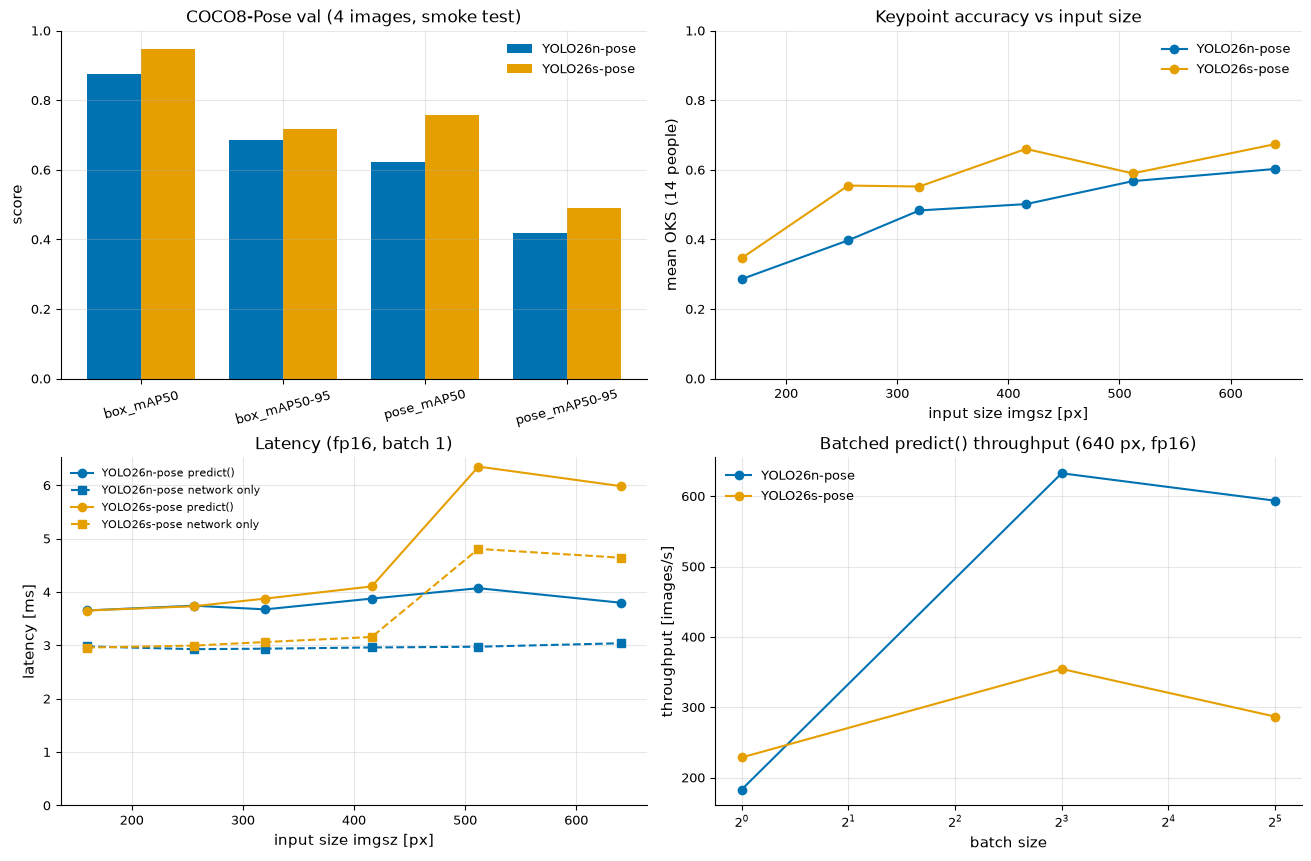

In [14]:
# --- Figure: official val metrics, OKS / latency vs input size, batched throughput ---
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
axes = axes.ravel()
metrics = ["box_mAP50", "box_mAP50-95", "pose_mAP50", "pose_mAP50-95"]
x = np.arange(len(metrics))
for i, mname in enumerate(models):
    axes[0].bar(x + (i - 0.5) * 0.38, val_df.loc[mname, metrics], width=0.38, label=mname, color=viz.color(i, unit=True))
axes[0].set_xticks(x, metrics, rotation=15)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("score")
axes[0].set_title("COCO8-Pose val (4 images, smoke test)")
axes[0].legend()
for i, mname in enumerate(models):
    d = sweep_df[sweep_df.model == mname]
    axes[1].plot(d.imgsz, d.mean_OKS, "o-", label=mname, color=viz.color(i, unit=True))
    axes[2].plot(d.imgsz, d.latency_ms, "o-", label=f"{mname} predict()", color=viz.color(i, unit=True))
    axes[2].plot(d.imgsz, d.network_ms, "s--", label=f"{mname} network only", color=viz.color(i, unit=True))
axes[1].set_xlabel("input size imgsz [px]")
axes[1].set_ylabel("mean OKS (14 people)")
axes[1].set_title("Keypoint accuracy vs input size")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[2].set_xlabel("input size imgsz [px]")
axes[2].set_ylabel("latency [ms]")
axes[2].set_ylim(0, None)
axes[2].set_title("Latency (fp16, batch 1)")
axes[2].legend(fontsize=8)
for i, mname in enumerate(models):
    d = batch_df[batch_df.model == mname]
    axes[3].plot(d.batch, d.images_per_s, "o-", label=mname, color=viz.color(i, unit=True))
axes[3].set_xscale("log", base=2)
axes[3].set_xlabel("batch size")
axes[3].set_ylabel("throughput [images/s]")
axes[3].set_title("Batched predict() throughput (640 px, fp16)")
axes[3].legend()
viz.savefig(fig, PROJECT, "keypoint_metrics")
plt.show()

Summary table (latency and VRAM at 640 px; OKS averaged over the 14 labelled val people).
The same numbers are written to `results/human_keypoints.json` for the README.

In [15]:
# --- Summary table + results JSON ---
at640 = sweep_df[sweep_df.imgsz == 640].set_index("model")
summary = pd.DataFrame({
    "params_M": pd.DataFrame(model_info).set_index("model")["params_M"],
    "GFLOPs@640": pd.DataFrame(model_info).set_index("model")["GFLOPs@640"],
    "box_mAP50-95": val_df["box_mAP50-95"],
    "pose_mAP50": val_df["pose_mAP50"],
    "pose_mAP50-95": val_df["pose_mAP50-95"],
    "mean_OKS@640": at640["mean_OKS"],
    "mean_OKS@320": sweep_df[sweep_df.imgsz == 320].set_index("model")["mean_OKS"],
    "latency_ms@640": at640["latency_ms"],
    "network_ms@640": at640["network_ms"],
    "peak_vram_MB@640": at640["peak_vram_MB"],
    "images_per_s@batch32": batch_df[batch_df.batch == 32].set_index("model")["images_per_s"],
    "peak_vram_MB@batch32": batch_df[batch_df.batch == 32].set_index("model")["peak_vram_MB"],
})
cvio.save_json({"hardware": "RTX 5060 Laptop GPU 8 GB, fp16, batch 1",
                "summary": summary.round(4).reset_index().to_dict(orient="records"),
                "imgsz_sweep": sweep_df.round(4).to_dict(orient="records"),
                "batch_throughput": batch_df.round(4).to_dict(orient="records")},
               RESULTS_DIR / "human_keypoints.json")
summary.round(3)

,params_M,GFLOPs@640,box_mAP50-95,pose_mAP50,pose_mAP50-95,mean_OKS@640,mean_OKS@320,latency_ms@640,network_ms@640,peak_vram_MB@640,images_per_s@batch32,peak_vram_MB@batch32
model,,,,,,,,,,,,
YOLO26n-pose,2.926,7.572,0.686,0.623,0.419,0.603,0.483,3.799,3.039,88.755,593.684,395.539
YOLO26s-pose,10.360,24.122,0.717,0.758,0.490,0.674,0.552,5.985,4.643,95.266,286.773,652.671


### Takeaways

* **One network, all people.** YOLO26-pose returns boxes and 17 keypoints per person in one pass,
  and the per-keypoint confidences reliably flag joints that are occluded or cut by the image
  border (the people at the edges of `bus.jpg`). Downstream logic should gate on them, as the
  arm rule does ("unknown" instead of a wrong "no").
* **OKS is scale-aware, so resolution matters.** Shrinking the input from 640 to 160 px roughly
  halves mean OKS for both models: for people far from the robot, input resolution matters as
  much as model size. With only 14 people the curves are noisy (non-monotonic steps).
* **s vs n.** YOLO26s-pose scores higher than n on every accuracy number here (box and pose mAP,
  mean OKS) for about 3-3.5x the parameters and FLOPs.
* **Batch-1 latency is mostly overhead-bound.** YOLO26n takes 3.7-4.1 ms per `predict()` call at
  every input size, YOLO26s the same up to 416 px and about 6 ms at 512-640 px (measured while
  other jobs shared the CPU, so the curves are noisy). The compute difference shows fully in batched
  throughput, where the n model processes about twice as many images per second as s at batch 32
  (594 vs 287 images/s). Peak memory stays below
  100 MB at batch 1 and below 1 GB at batch 32, so either model fits next to much larger
  perception models on an 8 GB card.
* **Do not over-read COCO8.** Four validation images give a pipeline check, not a benchmark:
  compare models on a real validation set (COCO val2017 or your own robot data) before choosing.

## Exercises

Solutions: `projects/07_pose_estimation/solutions/01_human_keypoints_solutions.py`
(run it with `flock /tmp/cv-gpu.lock python projects/07_pose_estimation/solutions/01_human_keypoints_solutions.py`).

**Exercise 1 - pose AP by hand.** Using `kp.oks_matrix`, compute pose AP at OKS 0.5 for
YOLO26s-pose on the 4 val images: sort all predictions by box score, greedily match each to the
unmatched GT with the highest OKS $\ge 0.5$, build the precision/recall curve and integrate it
(`cvlab.metrics.precision_recall` / `average_precision`). Compare with `pose_mAP50` above.

In [16]:
# --- Exercise 1: pose AP@0.5 from OKS matching ---
# TODO: collect (score, is_true_positive) for every prediction on the val images, then compute
# precision/recall and AP. Compare with val_df.loc["YOLO26s-pose", "pose_mAP50"].

**Exercise 2 - flip test-time augmentation.** Predict on the horizontally flipped image, map the
keypoints back ($x' = W - 1 - x$) and swap left/right joints with `kp.FLIP_IDX`, match the
flipped people to the original ones, and average the two keypoint sets. Does mean OKS improve at
`imgsz=320` and `640`?

In [17]:
# --- Exercise 2: flip test-time augmentation ---
# TODO: implement flip-TTA for one model and report mean OKS with and without it.

**Exercise 3 - a robust "stop" gesture.** Extend `arm_report` into a rule that fires only when
*both* wrists are above the shoulders *and* the elbows are reasonably straight (> 120 degrees), with
all keypoints at confidence $\ge 0.5$. Run it on all 8 COCO8-Pose images (train + val) and the two
sample images and list which people trigger it.

In [18]:
# --- Exercise 3: stop-gesture detector ---
# TODO: implement stop_gesture(kpts, conf) and evaluate it on the 10 images.